# 場域空間拓撲與車柱容量分布圖（純 OpenStreetMap 客製化向量底圖）

本 Notebook 以**純相對路徑**讀取 `econ-5166-student-kit/data/processed/` 資料，並向 OpenFreeMap（純 OpenStreetMap OpenMapTiles 向量圖磚 `.pbf`）抓取向量圖層自行渲染客製化底圖，完全移除 POI 圖示、浮水印與多餘文字，依序獨立輸出三張圖檔：
1. `basemap_osm_clean_raw.png`：純淨客製化 OpenStreetMap 彩色底圖（僅保留道路、建物、綠地與水體，無多餘圖標，可於 Cell 4 自由切換配色與圖層開關）。
2. `basemap_ntu_campus_highlighted.png`：校外灰階＋臺大主校區（含銘傳國小）淡黃色階＋平滑道路邊界細線（無任何站點圓點，作為共用底層）。
3. `map_field_topology_capacity.png` / `map_field_topology_capacity.pdf`：於上述底圖之上疊加 `120` 站校內（藍）／校外（橘紅）YouBike 車柱容量圓點（預設僅顯示單車站點圖標，保持畫面極簡整潔，並同步輸出供 LaTeX 快速載入之 PDF 地圖）。


In [1]:
from __future__ import annotations

import json
import math
import time
from pathlib import Path

import mapbox_vector_tile as mvt
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib import font_manager
from matplotlib.collections import LineCollection, PathCollection
from matplotlib.path import Path as MplPath
from PIL import Image, ImageDraw, ImageEnhance
from shapely.geometry import Point, Polygon, shape


def resolve_output_dir() -> Path:
    """Ensure outputs live in `proposal/contents/figures/map/` regardless of cwd."""
    cwd = Path.cwd().resolve()
    if cwd.name == "map" and (cwd / "ntu_campus_boundary.geojson").is_file():
        return cwd
    candidate = cwd / "contents" / "figures" / "map"
    if candidate.is_dir():
        return candidate
    for p in cwd.parents:
        c = p / "latex" / "Data_Science_and_Social_Inquiry" / "project" / "proposal" / "contents" / "figures" / "map"
        if c.is_dir():
            return c
    return cwd


def resolve_dssi_root(map_dir: Path) -> Path:
    """Locate `econ-5166-student-kit` via relative traversal from `map_dir`."""
    rel_candidate = (map_dir / "../../../../../../../econ-5166-student-kit").resolve()
    if (rel_candidate / "data" / "processed").is_dir():
        return rel_candidate
    for parent in map_dir.parents:
        candidate = parent / "econ-5166-student-kit"
        if (candidate / "data" / "processed").is_dir():
            return candidate
    raise FileNotFoundError("Cannot locate relative `econ-5166-student-kit/data/processed/` directory.")


def setup_cjk_font() -> str:
    candidates = [
        "PingFang TC", "PingFang HK", "Heiti TC", "STHeiti",
        "Noto Sans TC", "Noto Sans CJK TC", "Noto Sans CJK JP",
        "Microsoft JhengHei", "Arial Unicode MS",
    ]
    available = {f.name for f in font_manager.fontManager.ttflist}
    chosen = next((name for name in candidates if name in available), None)
    if chosen is None:
        raise RuntimeError("No Traditional Chinese font found on this system.")
    plt.rcParams.update({"font.family": chosen, "axes.unicode_minus": False})
    return chosen


OUT_DIR = resolve_output_dir()
DSSI_ROOT = resolve_dssi_root(OUT_DIR)
DATA_PROCESSED = DSSI_ROOT / "data" / "processed"

STATIONS_CSV = DATA_PROCESSED / "stations_in_field.csv"
FLOW_2024 = DATA_PROCESSED / "youbike_flow_hourly" / "youbike_flow_hourly_2024.parquet"
FLOW_2025 = DATA_PROCESSED / "youbike_flow_hourly" / "youbike_flow_hourly_2025.parquet"
TRAFFIC_2024 = DATA_PROCESSED / "youbike_traffic" / "YouBike_traffic_2024_v7.parquet"
TRAFFIC_2025 = DATA_PROCESSED / "youbike_traffic" / "YouBike_traffic_2025_v7.parquet"
NTU_BOUNDARY_JSON = OUT_DIR / "ntu_campus_boundary.geojson"
OSM_CACHE_DIR = OUT_DIR / "osm_pbf_cache"
OSM_CACHE_DIR.mkdir(parents=True, exist_ok=True)

OUT_RAW_BASEMAP = OUT_DIR / "basemap_osm_clean_raw.png"
OUT_STYLED_BASEMAP = OUT_DIR / "basemap_ntu_campus_highlighted.png"
OUT_CAPACITY_MAP = OUT_DIR / "map_field_topology_capacity.png"
OUT_CAPACITY_PDF = OUT_CAPACITY_MAP.with_suffix(".pdf")

chosen_font = setup_cjk_font()
print("CJK font:", chosen_font)
print("OUT_DIR:", OUT_DIR)
print("DSSI_ROOT:", DSSI_ROOT)


CJK font: PingFang TC
OUT_DIR: /Users/kdd/NTU/latex/Data_Science_and_Social_Inquiry/project/proposal/contents/figures/map
DSSI_ROOT: /Users/kdd/NTU/econ-5166-student-kit


In [2]:
# --- Load 120 stations & median usable dock capacity; set identical framing to ver6 Cell 10 ---
TILE = 256
LON_PAD, LAT_PAD = 0.004, 0.0015
ZOOM = 17
VEC_ZOOM = 14
MAP_DPI = 220

stations = pd.read_csv(STATIONS_CSV, dtype={"StationUID": str})
stations = stations.sort_values("last_seen").drop_duplicates("StationUID", keep="last")
stations["station_id"] = stations["StationID"].astype(str)
stations["name"] = stations["StationNameZh_tw"].str.removeprefix("YouBike2.0_")
stations = stations.set_index("station_id")[["name", "PositionLat", "PositionLon"]].rename(
    columns={"PositionLat": "latitude", "PositionLon": "longitude"}
)

flow_cols = ["station_id", "in_service", "AvailableRentBikes_start", "AvailableReturnBikes_start"]
fh = pd.concat(
    [pd.read_parquet(FLOW_2024, columns=flow_cols), pd.read_parquet(FLOW_2025, columns=flow_cols)],
    ignore_index=True,
)
fh["station_id"] = fh["station_id"].astype(str)
valid = (
    (fh["in_service"] == 1)
    & fh["AvailableRentBikes_start"].notna()
    & fh["AvailableReturnBikes_start"].notna()
)
fv = fh.loc[valid, ["station_id", "AvailableRentBikes_start", "AvailableReturnBikes_start"]].copy()
fv["docks"] = fv["AvailableRentBikes_start"] + fv["AvailableReturnBikes_start"]
cap = fv.groupby("station_id")["docks"].median().rename("capacity")
t24 = pd.read_parquet(TRAFFIC_2024, columns=["rent_station_id", "return_station_id"])
t25 = pd.read_parquet(TRAFFIC_2025, columns=["rent_station_id", "return_station_id"])
trips = pd.concat([t24, t25], ignore_index=True)
del t24, t25
for _c in ("rent_station_id", "return_station_id"):
    trips[_c] = trips[_c].astype(str)
vol = (trips.loc[trips["rent_station_id"] != "-1", "rent_station_id"].value_counts()
       .add(trips.loc[trips["return_station_id"] != "-1", "return_station_id"].value_counts(), fill_value=0))
del trips
df = stations.join(cap, how="inner").join(vol.rename("volume")).fillna({"volume": 0.0}).reset_index()

lon_min, lat_min = df["longitude"].min() - LON_PAD, df["latitude"].min() - LAT_PAD
lon_max, lat_max = df["longitude"].max() + LON_PAD, df["latitude"].max() + LAT_PAD


def lon_to_x(lon):
    return (np.asarray(lon, dtype=float) + 180.0) / 360.0 * (2 ** ZOOM) * TILE


def lat_to_y(lat):
    r = np.radians(np.asarray(lat, dtype=float))
    return (1.0 - np.log(np.tan(r) + 1.0 / np.cos(r)) / np.pi) / 2.0 * (2 ** ZOOM) * TILE


X0, Y0 = float(lon_to_x(lon_min)), float(lat_to_y(lat_max))
MAP_W = int(round(float(lon_to_x(lon_max)) - X0))
MAP_H = int(round(float(lat_to_y(lat_min)) - Y0))


def to_px(lon, lat):
    return lon_to_x(lon) - X0, lat_to_y(lat) - Y0


print(f"Stations: {len(df)}, Total docks: {int(round(df['capacity'].sum())):,}, Total volume: {int(round(df['volume'].sum())):,}, Canvas: {MAP_W} x {MAP_H} px")


Stations: 120, Total docks: 3,714, Total volume: 31,391,665, Canvas: 2600 x 1772 px


In [3]:
# --- Step 1: Fetch & decode pure OpenStreetMap OpenMapTiles vector tiles (.pbf) ---
FORCE_REDOWNLOAD_PBF = False
HEADERS = {"User-Agent": "NTU-YouBike-analysis/2.0 (academic proposal figure)"}

vec_scale = (2 ** VEC_ZOOM) / (2 ** ZOOM) / TILE
tx0, ty0 = int(X0 * vec_scale), int(Y0 * vec_scale)
tx1, ty1 = int((X0 + MAP_W - 1) * vec_scale), int((Y0 + MAP_H - 1) * vec_scale)
tile_jobs = [(tx, ty) for ty in range(ty0, ty1 + 1) for tx in range(tx0, tx1 + 1)]

tile_template = None
decoded_tiles: dict[tuple[int, int], dict] = {}

for tx, ty in tile_jobs:
    pbf_path = OSM_CACHE_DIR / f"osm_z{VEC_ZOOM}_{tx}_{ty}.pbf"
    if (not pbf_path.is_file()) or FORCE_REDOWNLOAD_PBF:
        if tile_template is None:
            tj = requests.get("https://tiles.openfreemap.org/planet", headers=HEADERS, timeout=15).json()
            tile_template = tj["tiles"][0]
        url = tile_template.format(z=VEC_ZOOM, x=tx, y=ty)
        for attempt in range(4):
            try:
                resp = requests.get(url, headers=HEADERS, timeout=25)
                if resp.status_code == 200:
                    pbf_path.write_bytes(resp.content)
                    break
            except requests.RequestException:
                pass
            time.sleep(1.2 * (attempt + 1))
    decoded_tiles[(tx, ty)] = mvt.decode(
        pbf_path.read_bytes(), default_options={"y_coord_down": True}
    )

print(f"Loaded {len(decoded_tiles)} OpenStreetMap z{VEC_ZOOM} vector tiles: {tile_jobs}")


Loaded 4 OpenStreetMap z14 vector tiles: [(13722, 7014), (13723, 7014), (13722, 7015), (13723, 7015)]


In [4]:
# --- Step 2: Customizable OpenStreetMap Vector Basemap Renderer (zero POI / clutter) ---
OSM_STYLE = "osm_clean_color"  # Options: "osm_clean_color", "osm_minimal_gray", "osm_blueprint"
SHOW_PARKS = True
SHOW_WATER = True
SHOW_BUILDINGS = True
SHOW_FOOTPATHS = True

STYLE_PRESETS = {
    "osm_clean_color": {
        "bg": "#F4F3EF",
        "grass": "#DFECD4",
        "wood": "#CBE0BE",
        "pitch": "#D6E9C8",
        "water": "#B6DDF0",
        "building": "#E3DFD7",
        "road_casing": "#C8CDD3",
        "road_major": "#FCE9B8",
        "road_secondary": "#FFF6D6",
        "road_minor": "#FFFFFF",
        "footpath": "#DAD8D0",
    },
    "osm_minimal_gray": {
        "bg": "#F5F5F4",
        "grass": "#EAEBE8",
        "wood": "#E1E3DF",
        "pitch": "#E6E8E4",
        "water": "#DCE4E8",
        "building": "#E6E6E4",
        "road_casing": "#CFCFD2",
        "road_major": "#FFFFFF",
        "road_secondary": "#FFFFFF",
        "road_minor": "#FFFFFF",
        "footpath": "#DFDFDC",
    },
    "osm_blueprint": {
        "bg": "#EFF4FA",
        "grass": "#E2ECF5",
        "wood": "#D6E4F0",
        "pitch": "#DCE8F4",
        "water": "#BED9EE",
        "building": "#DDE6F0",
        "road_casing": "#B8C8D8",
        "road_major": "#FFFFFF",
        "road_secondary": "#FFFFFF",
        "road_minor": "#F8FBFE",
        "footpath": "#CEDAE6",
    },
}
pal = STYLE_PRESETS[OSM_STYLE]


def signed_area(pts: np.ndarray) -> float:
    x, y = pts[:, 0], pts[:, 1]
    return 0.5 * float(np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y))


def poly_to_mpl_path(rings: list, tx: int, ty: int, scale: float, span_px: float) -> MplPath | None:
    verts_list, codes_list = [], []
    for r_idx, ring in enumerate(rings):
        if len(ring) < 3:
            continue
        arr = np.asarray(ring, dtype=float)
        if not np.allclose(arr[0], arr[-1]):
            arr = np.vstack([arr, arr[0]])
        px = np.column_stack([
            tx * span_px + arr[:, 0] * scale - X0,
            ty * span_px + arr[:, 1] * scale - Y0,
        ])
        # Enforce consistent winding (exterior > 0, interior holes < 0)
        sa = signed_area(px[:-1])
        if (r_idx == 0 and sa < 0) or (r_idx > 0 and sa > 0):
            px = px[::-1]
        codes = np.full(len(px), MplPath.LINETO, dtype=np.uint8)
        codes[0] = MplPath.MOVETO
        codes[-1] = MplPath.CLOSEPOLY
        verts_list.append(px)
        codes_list.append(codes)
    if not verts_list:
        return None
    return MplPath(np.vstack(verts_list), np.concatenate(codes_list))


def iter_tile_features(layer_name: str):
    span_px = (2 ** (ZOOM - VEC_ZOOM)) * TILE
    for (tx, ty), dec in decoded_tiles.items():
        layer = dec.get(layer_name)
        if not layer:
            continue
        scale = span_px / layer.get("extent", 4096)
        for feat in layer["features"]:
            yield feat, tx, ty, scale, span_px


grass_paths, wood_paths, pitch_paths = [], [], []
water_paths, water_lines, building_paths = [], [], []
road_segs = {"major": [], "secondary": [], "tertiary": [], "minor": [], "path": []}

if SHOW_PARKS:
    for feat, tx, ty, sc, sp in iter_tile_features("landcover"):
        g, props = feat["geometry"], feat["properties"]
        cls = props.get("class")
        target = wood_paths if cls == "wood" else grass_paths
        polys = [g["coordinates"]] if g["type"] == "Polygon" else (g["coordinates"] if g["type"] == "MultiPolygon" else [])
        for p in polys:
            mp = poly_to_mpl_path(p, tx, ty, sc, sp)
            if mp is not None:
                target.append(mp)
    for feat, tx, ty, sc, sp in iter_tile_features("landuse"):
        g, props = feat["geometry"], feat["properties"]
        if props.get("class") not in ("pitch", "playground", "track"):
            continue
        polys = [g["coordinates"]] if g["type"] == "Polygon" else (g["coordinates"] if g["type"] == "MultiPolygon" else [])
        for p in polys:
            mp = poly_to_mpl_path(p, tx, ty, sc, sp)
            if mp is not None:
                pitch_paths.append(mp)

if SHOW_WATER:
    for feat, tx, ty, sc, sp in iter_tile_features("water"):
        g = feat["geometry"]
        polys = [g["coordinates"]] if g["type"] == "Polygon" else (g["coordinates"] if g["type"] == "MultiPolygon" else [])
        for p in polys:
            mp = poly_to_mpl_path(p, tx, ty, sc, sp)
            if mp is not None:
                water_paths.append(mp)
    for feat, tx, ty, sc, sp in iter_tile_features("waterway"):
        if feat["properties"].get("class") != "river":
            continue
        g = feat["geometry"]
        lines = [g["coordinates"]] if g["type"] == "LineString" else (g["coordinates"] if g["type"] == "MultiLineString" else [])
        for ln in lines:
            arr = np.asarray(ln, dtype=float)
            water_lines.append(np.column_stack([tx * sp + arr[:, 0] * sc - X0, ty * sp + arr[:, 1] * sc - Y0]))

if SHOW_BUILDINGS:
    for feat, tx, ty, sc, sp in iter_tile_features("building"):
        g = feat["geometry"]
        polys = [g["coordinates"]] if g["type"] == "Polygon" else (g["coordinates"] if g["type"] == "MultiPolygon" else [])
        for p in polys:
            mp = poly_to_mpl_path(p, tx, ty, sc, sp)
            if mp is not None:
                building_paths.append(mp)

for feat, tx, ty, sc, sp in iter_tile_features("transportation"):
    g, props = feat["geometry"], feat["properties"]
    cls, sub = props.get("class"), props.get("subclass")
    if cls in ("motorway", "trunk", "primary"):
        bucket = "major"
    elif cls == "secondary":
        bucket = "secondary"
    elif cls == "tertiary":
        bucket = "tertiary"
    elif cls in ("minor", "service"):
        bucket = "minor"
    elif cls == "path" and SHOW_FOOTPATHS and sub != "steps":
        bucket = "path"
    else:
        continue
    lines = [g["coordinates"]] if g["type"] == "LineString" else (g["coordinates"] if g["type"] == "MultiLineString" else [])
    for ln in lines:
        if len(ln) >= 2:
            arr = np.asarray(ln, dtype=float)
            road_segs[bucket].append(np.column_stack([tx * sp + arr[:, 0] * sc - X0, ty * sp + arr[:, 1] * sc - Y0]))

fig_r = plt.figure(figsize=(MAP_W / MAP_DPI, MAP_H / MAP_DPI), dpi=MAP_DPI, facecolor=pal["bg"])
ax_r = fig_r.add_axes([0.0, 0.0, 1.0, 1.0])
ax_r.set_facecolor(pal["bg"])
ax_r.set_xlim(0, MAP_W)
ax_r.set_ylim(MAP_H, 0)
ax_r.set_axis_off()

if grass_paths:
    ax_r.add_collection(PathCollection(grass_paths, facecolors=pal["grass"], edgecolors="none", zorder=1.1))
if wood_paths:
    ax_r.add_collection(PathCollection(wood_paths, facecolors=pal["wood"], edgecolors="none", zorder=1.2))
if pitch_paths:
    ax_r.add_collection(PathCollection(pitch_paths, facecolors=pal["pitch"], edgecolors="none", zorder=1.3))
if water_paths:
    ax_r.add_collection(PathCollection(water_paths, facecolors=pal["water"], edgecolors="none", zorder=1.8))
if water_lines:
    ax_r.add_collection(LineCollection(water_lines, colors=pal["water"], linewidths=3.8, capstyle="round", joinstyle="round", zorder=1.9))
if building_paths:
    ax_r.add_collection(PathCollection(building_paths, facecolors=pal["building"], edgecolors="none", zorder=2.2))

if road_segs["path"]:
    ax_r.add_collection(LineCollection(road_segs["path"], colors=pal["footpath"], linewidths=0.75, capstyle="round", joinstyle="round", alpha=0.82, zorder=2.8))

# Road casing + fill hierarchy
road_specs = [
    ("minor", 2.0, 1.35, pal["road_minor"], 3.1, 3.6),
    ("tertiary", 3.2, 2.25, pal["road_minor"], 3.2, 3.7),
    ("secondary", 4.4, 3.25, pal["road_secondary"], 3.3, 3.8),
    ("major", 5.5, 4.10, pal["road_major"], 3.4, 3.9),
]
for bkt, w_case, w_fill, col_fill, z_c, z_f in road_specs:
    if road_segs[bkt]:
        ax_r.add_collection(LineCollection(road_segs[bkt], colors=pal["road_casing"], linewidths=w_case, capstyle="round", joinstyle="round", zorder=z_c))
        ax_r.add_collection(LineCollection(road_segs[bkt], colors=col_fill, linewidths=w_fill, capstyle="round", joinstyle="round", zorder=z_f))

fig_r.savefig(OUT_RAW_BASEMAP, dpi=MAP_DPI, facecolor=pal["bg"], pad_inches=0.0)
plt.close(fig_r)

raw_basemap = Image.open(OUT_RAW_BASEMAP).convert("RGB")
assert raw_basemap.size == (MAP_W, MAP_H), f"Expected {(MAP_W, MAP_H)}, got {raw_basemap.size}"
print(f"Saved clean customizable OSM basemap ({OSM_STYLE}): {OUT_RAW_BASEMAP} ({raw_basemap.size[0]} x {raw_basemap.size[1]} px)")


Saved clean customizable OSM basemap (osm_clean_color): /Users/kdd/NTU/latex/Data_Science_and_Social_Inquiry/project/proposal/contents/figures/map/basemap_osm_clean_raw.png (2600 x 1772 px)


In [5]:
# --- Step 3: Smooth road-bounded NTU main campus (grayscale outside, pale yellow inside, thin border) ---
NTU_ROAD_BOUNDARY_LATLON = [
    (25.013200, 121.539430),
    (25.011331, 121.537161),
    (25.011517, 121.537083),
    (25.012615, 121.536452),
    (25.013381, 121.535894),
    (25.014001, 121.535278),
    (25.015324, 121.533838),
    (25.016355, 121.532771),
    (25.016787, 121.533284),
    (25.017005, 121.533410),
    (25.022244, 121.534481),
    (25.022282, 121.536698),
    (25.022239, 121.537114),
    (25.022190, 121.537316),
    (25.022036, 121.537694),
    (25.021639, 121.538246),
    (25.021330, 121.538824),
    (25.021159, 121.539530),
    (25.021037, 121.543465),
    (25.020947, 121.544090),
    (25.020830, 121.544448),
    (25.020664, 121.544735),
    (25.019111, 121.546385),
    (25.015933, 121.542545),
    (25.013200, 121.539430),
]

if NTU_BOUNDARY_JSON.is_file():
    gj = json.loads(NTU_BOUNDARY_JSON.read_text(encoding="utf-8"))
    campus_poly = shape(gj["geometry"] if gj.get("type") == "Feature" else gj)
else:
    campus_poly = Polygon([(lon, lat) for lat, lon in NTU_ROAD_BOUNDARY_LATLON])

COL_CAMPUS_EDGE = "#B89122"

gray_l = raw_basemap.convert("L")
gray_crisp = ImageEnhance.Contrast(gray_l).enhance(1.15)
gray_arr = np.asarray(gray_crisp, dtype=np.float32) / 255.0

out_val = (0.18 + 0.82 * gray_arr) * 255.0
out_rgb = np.repeat(out_val[..., None], 3, axis=2)

light_yellow = np.array([255.0, 247.0, 198.0], dtype=np.float32)
dark_olive = np.array([88.0, 75.0, 28.0], dtype=np.float32)
t = np.clip(gray_arr, 0.0, 1.0)[..., None]
campus_rgb = dark_olive + t * (light_yellow - dark_olive)

mask_img = Image.new("L", raw_basemap.size, 0)
draw = ImageDraw.Draw(mask_img)
ext_lon, ext_lat = zip(*campus_poly.exterior.coords)
px_x, px_y = to_px(ext_lon, ext_lat)
draw.polygon(list(zip(px_x.tolist(), px_y.tolist())), fill=255)

mask = (np.asarray(mask_img, dtype=np.float32) / 255.0)[..., None]
styled_arr = np.clip(out_rgb * (1.0 - mask) + campus_rgb * mask, 0, 255).astype(np.uint8)
styled_base = Image.fromarray(styled_arr).convert("RGBA")

# Bake thin anti-aliased boundary line directly into the reusable styled basemap
fig_b = plt.figure(figsize=(MAP_W / MAP_DPI, MAP_H / MAP_DPI), dpi=MAP_DPI)
ax_b = fig_b.add_axes([0.0, 0.0, 1.0, 1.0])
ax_b.imshow(styled_base)
ax_b.plot(px_x, px_y, color=COL_CAMPUS_EDGE, lw=1.0, alpha=0.88, zorder=2)
ax_b.set_xlim(0, MAP_W)
ax_b.set_ylim(MAP_H, 0)
ax_b.set_axis_off()
fig_b.savefig(OUT_STYLED_BASEMAP, dpi=MAP_DPI, pad_inches=0.0)
plt.close(fig_b)

styled_check = Image.open(OUT_STYLED_BASEMAP)
assert styled_check.size == (MAP_W, MAP_H), f"Expected {(MAP_W, MAP_H)}, got {styled_check.size}"
print(f"Saved reusable styled basemap: {OUT_STYLED_BASEMAP} ({styled_check.size[0]} x {styled_check.size[1]} px)")


Saved reusable styled basemap: /Users/kdd/NTU/latex/Data_Science_and_Social_Inquiry/project/proposal/contents/figures/map/basemap_ntu_campus_highlighted.png (2600 x 1772 px)


OSM 全圖站點 174 站 -> 研究範圍 120 站（校內 63、校外 57）＋ 範圍外灰點 54 站


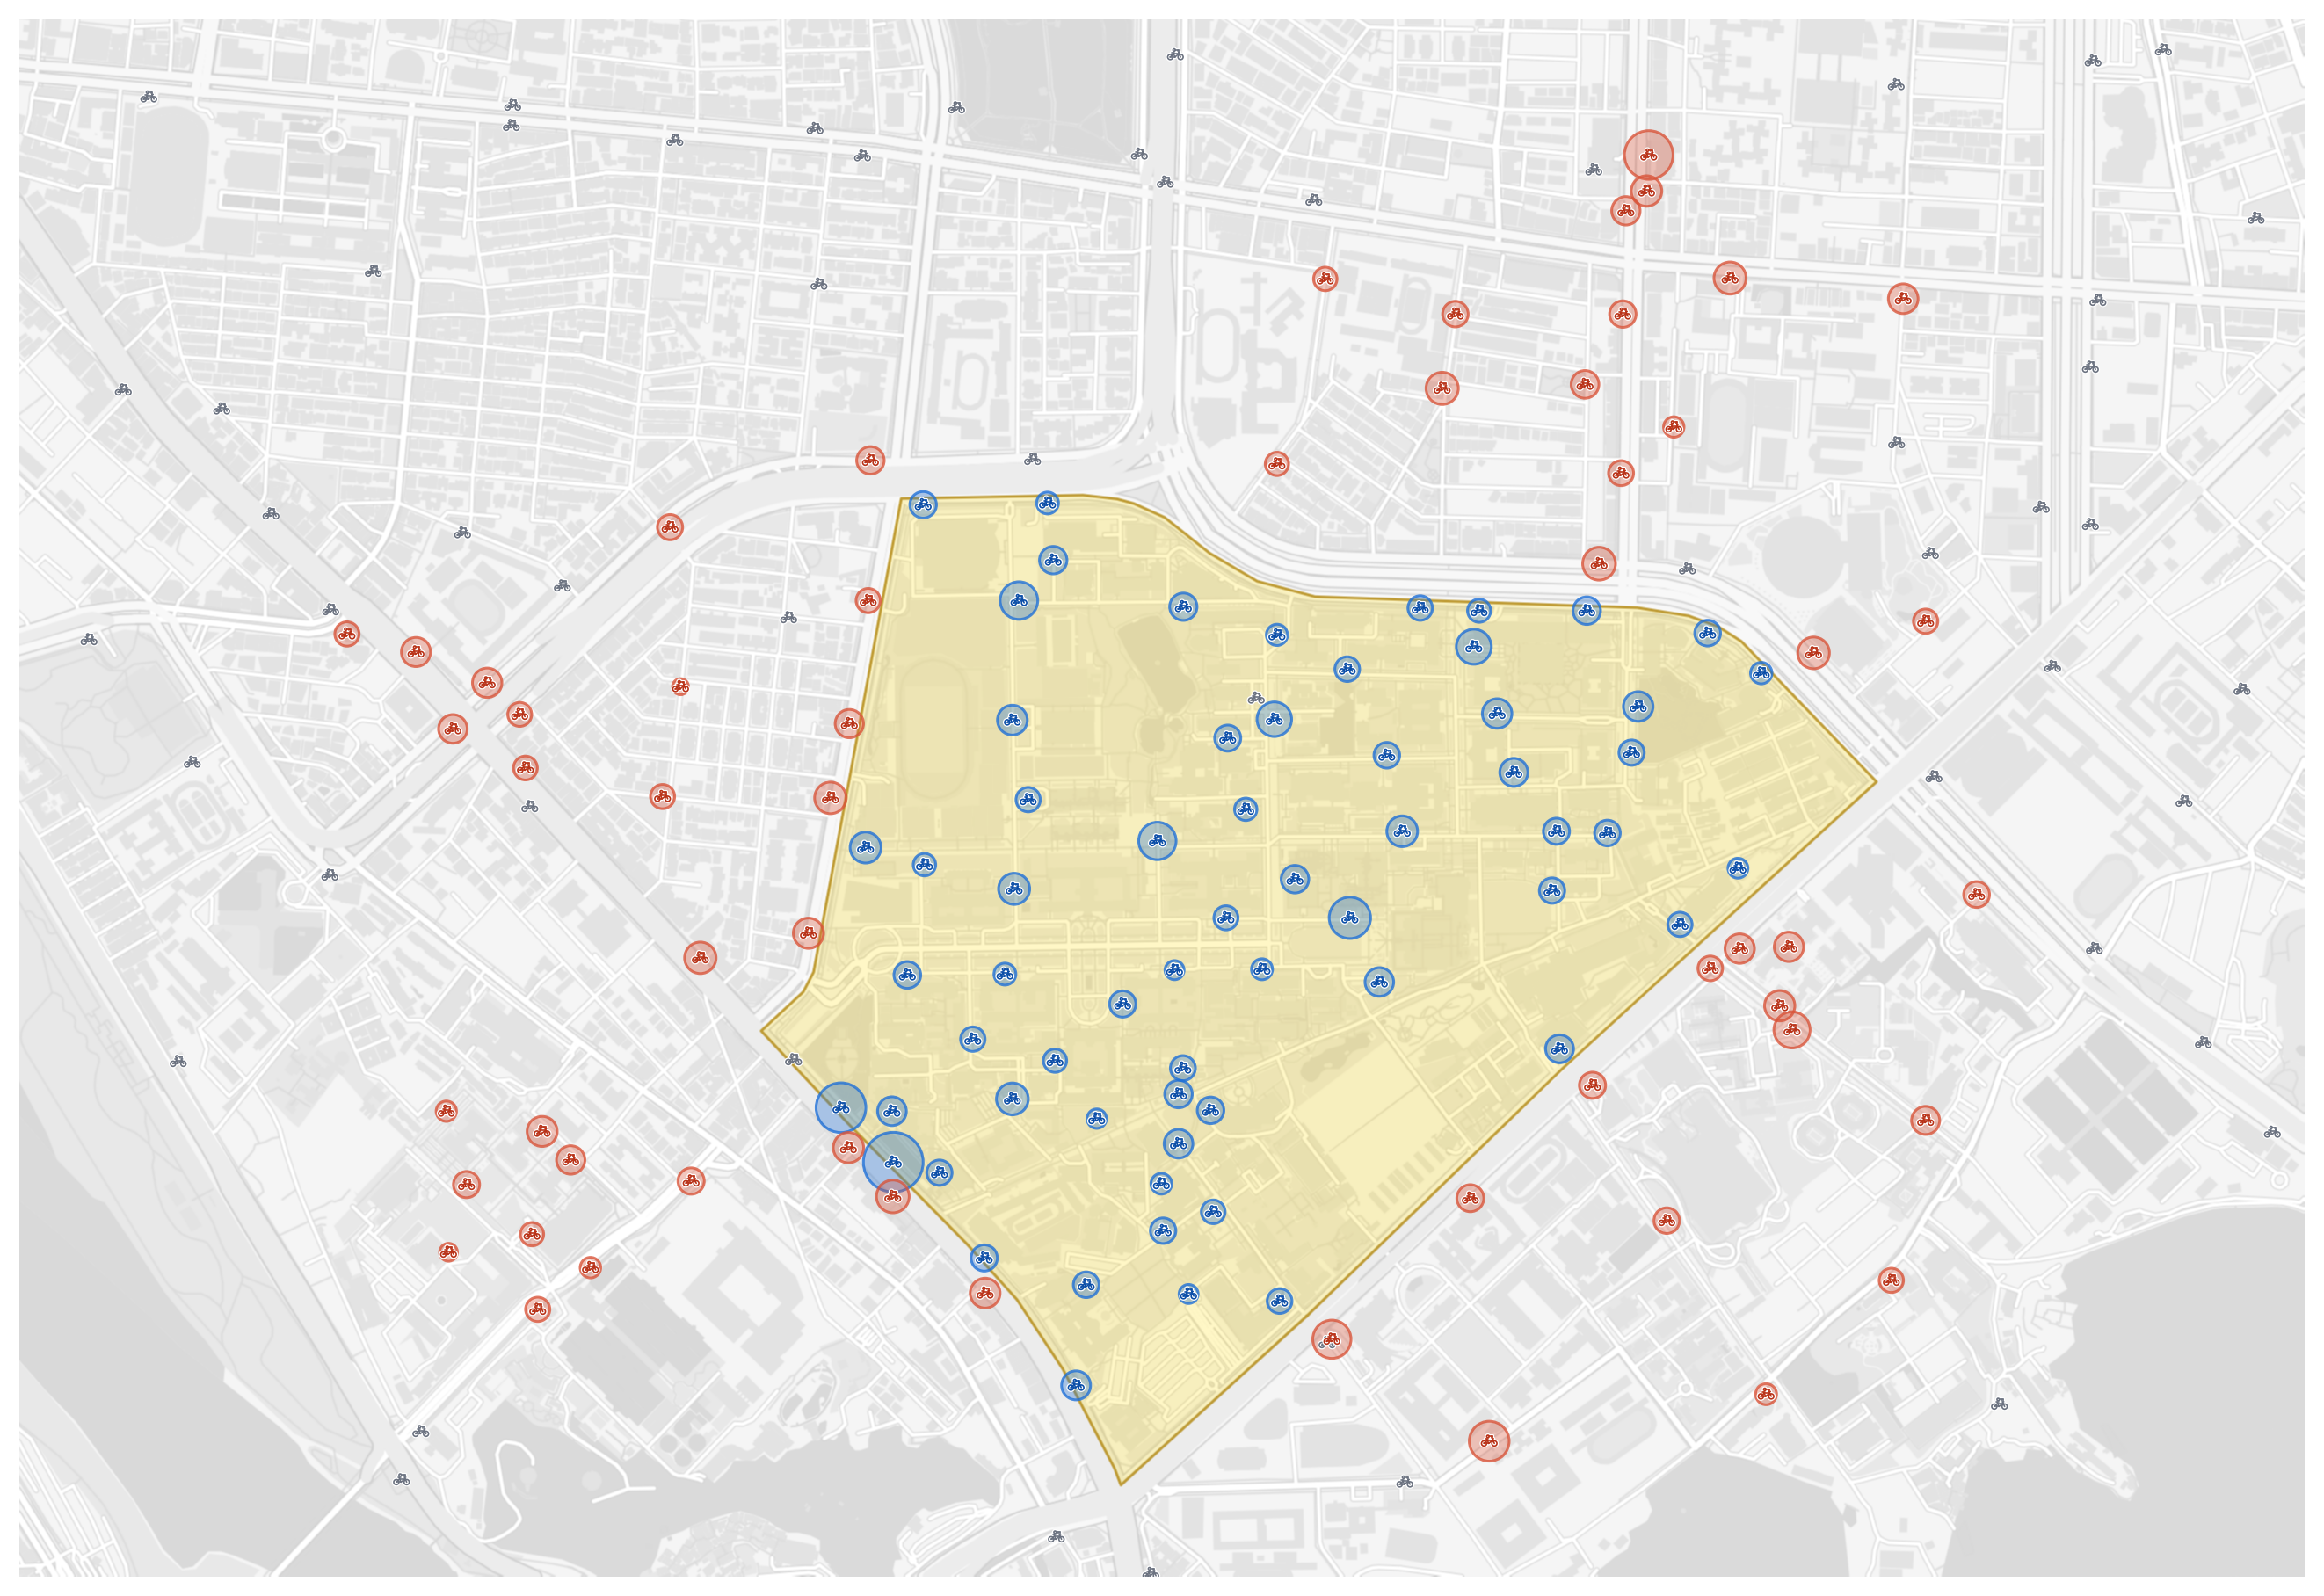

Saved map: /Users/kdd/NTU/latex/Data_Science_and_Social_Inquiry/project/proposal/contents/figures/map/map_field_topology_capacity.png (2600 x 1772 px) + map_field_topology_capacity.pdf


In [6]:
# --- Step 4: Mark ALL 174 OSM bicycle_rental icons (non-120 in grey) + 120 station flow circles ---
from matplotlib.patches import Circle

ICON_SCALE = 10.5             # Compact OSM default icon size (~18 px wide)
FLOW_R_MIN, FLOW_R_MAX = 7.0, 34.0
FLOW_FILL_ALPHA = 0.33

# Palette: 120 research stations (On-campus Blue / Off-campus Coral Red) vs. Non-scope Grey
COL_IN_CIRCLE = "#1D6FD8"
COL_OUT_CIRCLE = "#D95338"
COL_IN_ICON = "#0B4EA8"
COL_OUT_ICON = "#B93218"
COL_NONSCOPE_ICON = "#6B7280"


def px_to_lonlat(px: float, py: float) -> tuple[float, float]:
    gx, gy = px + X0, py + Y0
    lon = gx / ((2 ** ZOOM) * TILE) * 360.0 - 180.0
    n = math.pi - 2.0 * math.pi * gy / ((2 ** ZOOM) * TILE)
    lat = math.degrees(math.atan(0.5 * (math.exp(n) - math.exp(-n))))
    return lon, lat


# 1. Extract ALL official OpenStreetMap `amenity=bicycle_rental` POIs in the screenshot bbox
span_px = (2 ** (ZOOM - VEC_ZOOM)) * TILE
osm_stations = []
for (tx, ty), dec in sorted(decoded_tiles.items()):
    poi = dec.get("poi", {})
    ext = poi.get("extent", 4096)
    sc = span_px / ext
    for feat in poi.get("features", []):
        pr = feat["properties"]
        if pr.get("class") == "bicycle_rental" or pr.get("subclass") == "bicycle_rental":
            g = feat["geometry"]
            if g["type"] != "Point":
                continue
            lx, ly = g["coordinates"]
            if not (0 <= lx < ext and 0 <= ly < ext):
                continue
            px = tx * span_px + lx * sc - X0
            py = ty * span_px + ly * sc - Y0
            if 0 <= px <= MAP_W and 0 <= py <= MAP_H:
                lon, lat = px_to_lonlat(px, py)
                osm_stations.append({
                    "osm_name": pr.get("name", ""),
                    "px": px,
                    "py": py,
                    "lon": lon,
                    "lat": lat,
                })

osm_df = pd.DataFrame(osm_stations)

# 2. Match our 120 research-scope stations 1-to-1 to the official OSM POIs
m_lat = 110773.0
m_lon = 111320.0 * math.cos(math.radians(25.017))
osm_df["in_study"] = False
osm_df["on_campus"] = False
osm_df["volume"] = 0.0

for r in df.itertuples(index=False):
    nm_hits = osm_df.index[osm_df["osm_name"] == r.name].tolist()
    if nm_hits:
        idx = nm_hits[0]
    else:
        dists = np.hypot((osm_df["lon"] - r.longitude) * m_lon, (osm_df["lat"] - r.latitude) * m_lat)
        idx = int(dists.idxmin())
    osm_df.loc[idx, "in_study"] = True
    osm_df.loc[idx, "on_campus"] = bool(campus_poly.contains(Point(r.longitude, r.latitude)))
    osm_df.loc[idx, "volume"] = float(r.volume)

n_study = int(osm_df["in_study"].sum())
n_in = int((osm_df["in_study"] & osm_df["on_campus"]).sum())
n_out = int((osm_df["in_study"] & ~osm_df["on_campus"]).sum())
n_grey = int((~osm_df["in_study"]).sum())
print(f"OSM 全圖站點 {len(osm_df)} 站 -> 研究範圍 {n_study} 站（校內 {n_in}、校外 {n_out}）＋ 範圍外灰點 {n_grey} 站")


def flow_radius(v: float, vmax: float) -> float:
    return FLOW_R_MIN + (FLOW_R_MAX - FLOW_R_MIN) * math.sqrt(abs(v) / vmax) if vmax > 0 else FLOW_R_MIN


def draw_osm_bicycle_rental_icon(ax, cx: float, cy: float, s: float, color: str, zorder: float) -> None:
    """Draw compact OSM Carto-style `bicycle_rental` icon (bicycle + key) with crisp white halo."""
    lw_fg = 0.54
    lw_bg = 1.35
    segs = [
        [(-0.56, 0.24), (-0.06, 0.24)],
        [(-0.56, 0.24), (-0.20, -0.10)],
        [(-0.06, 0.24), (-0.24, -0.22)],
        [(-0.36, -0.23), (-0.12, -0.23)],
        [(-0.20, -0.10), (0.38, -0.10)],
        [(-0.06, 0.24), (0.38, -0.10)],
        [(0.56, 0.24), (0.34, -0.26)],
        [(0.34, -0.26), (0.47, -0.28)],
        [(-0.02, -0.52), (0.38, -0.52)],
        [(0.24, -0.52), (0.24, -0.38)],
        [(0.36, -0.52), (0.36, -0.36)],
    ]
    scaled_segs = [[(cx + x0 * s, cy + y0 * s), (cx + x1 * s, cy + y1 * s)] for (x0, y0), (x1, y1) in segs]
    wheel_coords = [(-0.56 * s, 0.24 * s, 0.28 * s), (0.56 * s, 0.24 * s, 0.28 * s)]
    key_bow = (-0.14 * s, -0.52 * s, 0.13 * s)

    for dx, dy, r in (*wheel_coords, key_bow):
        ax.add_patch(Circle((cx + dx, cy + dy), r, facecolor="none", edgecolor="white", linewidth=lw_bg, zorder=zorder))
    ax.add_collection(LineCollection(scaled_segs, colors="white", linewidths=lw_bg, capstyle="round", joinstyle="round", zorder=zorder))

    for dx, dy, r in (*wheel_coords, key_bow):
        ax.add_patch(Circle((cx + dx, cy + dy), r, facecolor="none", edgecolor=color, linewidth=lw_fg, zorder=zorder + 0.1))
    ax.add_collection(LineCollection(scaled_segs, colors=color, linewidths=lw_fg, capstyle="round", joinstyle="round", zorder=zorder + 0.1))


base_layer = Image.open(OUT_STYLED_BASEMAP).convert("RGBA")
fig = plt.figure(figsize=(MAP_W / MAP_DPI, MAP_H / MAP_DPI), dpi=MAP_DPI)
ax = fig.add_axes([0.0, 0.0, 1.0, 1.0])
ax.imshow(base_layer, zorder=0)
ax.set_xlim(0, MAP_W)
ax.set_ylim(MAP_H, 0)
ax.set_axis_off()

# Layer 1 (above basemap & boundary): Translucent flow circles for the 120 study stations (largest first)
study_df = osm_df[osm_df["in_study"]].sort_values("volume", ascending=False).reset_index(drop=True)
vmax = float(study_df["volume"].max())
for idx, row in enumerate(study_df.itertuples(index=False)):
    rad = flow_radius(row.volume, vmax)
    c_fill = COL_IN_CIRCLE if row.on_campus else COL_OUT_CIRCLE
    z_c = 3.0 + idx * 0.01
    ax.add_patch(Circle((row.px, row.py), rad, facecolor=c_fill, alpha=FLOW_FILL_ALPHA, edgecolor="none", zorder=z_c))
    ax.add_patch(Circle((row.px, row.py), rad, facecolor="none", edgecolor=c_fill, alpha=0.78, linewidth=1.0, zorder=z_c + 0.005))

# Layer 2 (top): Non-study OSM stations in grey, then 120 study stations in blue / coral red
for row in osm_df[~osm_df["in_study"]].itertuples(index=False):
    draw_osm_bicycle_rental_icon(ax, row.px, row.py, ICON_SCALE, COL_NONSCOPE_ICON, zorder=6.0)
for row in study_df.itertuples(index=False):
    c_icon = COL_IN_ICON if row.on_campus else COL_OUT_ICON
    draw_osm_bicycle_rental_icon(ax, row.px, row.py, ICON_SCALE, c_icon, zorder=7.0)

fig.savefig(OUT_CAPACITY_MAP, dpi=MAP_DPI, pad_inches=0.0)
fig.savefig(OUT_CAPACITY_PDF, dpi=MAP_DPI, pad_inches=0.0)
plt.show()
plt.close(fig)
out_check = Image.open(OUT_CAPACITY_MAP)
assert out_check.size == (MAP_W, MAP_H), f"Expected {(MAP_W, MAP_H)}, got {out_check.size}"
assert OUT_CAPACITY_PDF.is_file() and OUT_CAPACITY_PDF.stat().st_size > 0
print(f"Saved map: {OUT_CAPACITY_MAP} ({out_check.size[0]} x {out_check.size[1]} px) + {OUT_CAPACITY_PDF.name}")
